<a href="https://colab.research.google.com/github/Samarth-Kanodia/Twitter-Sentiment-Analysis/blob/main/Twitter%20Sentiment%20Analysis.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Problem Statement:

The objective of this task is to detect hate speech in tweets. For the sake of simplicity, we say a tweet contains hate speech if it has a racist or sexist sentiment associated with it. So, the task is to classify racist or sexist tweets from other tweets.

Following attributes are present in the given dataset:
  <ul>
    <li> id </li>
    <li> label </li>
    <li> tweet </li>
  </ul>

Formally, given a training sample of tweets and labels, where label '1' denotes the tweet is racist/sexist and label '0' denotes the tweet is not racist/sexist, your objective is to predict the labels on the test dataset.

**How to run:** *Runtime → Run all*. When prompted, upload `train.csv` and `test.csv` (skipped if they are already in the session). A full run takes roughly an hour, mostly the SVM and XGBoost tuning cells.

In [ ]:
!pip install -q gensim wordcloud xgboost

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 27.8/27.8 MB 61.3 MB/s eta 0:00:00


In [ ]:
import re    # for regular expressions
import nltk  # for text manipulation
import string
import warnings
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

In [ ]:
pd.set_option("display.max_colwidth", 200)
warnings.filterwarnings("ignore", category=DeprecationWarning)

In [ ]:
# enable the rendering of Matplotlib plots directly below code cells
%matplotlib inline

In [ ]:
import os

# upload train.csv and test.csv if they are not already in this Colab session
if not (os.path.exists('train.csv') and os.path.exists('test.csv')):
    from google.colab import files
    files.upload()

train = pd.read_csv('train.csv')
test = pd.read_csv('test.csv')

In [ ]:
train.shape

(31962, 3)

In [ ]:
train.head()

,id,label,tweet
0,1,0,@user when a father is dysfunctional and is so selfish he drags his kids into his dysfunction. #run
1,2,0,@user @user thanks for #lyft credit i can't use cause they don't offer wheelchair vans in pdx. #disapointed #getthanked
2,3,0,bihday your majesty
3,4,0,#model i love u take with u all the time in urð±!!! ðððð ð¦ð¦ð¦
4,5,0,factsguide: society now #motivation


In [ ]:
train.shape

(31962, 3)

In [ ]:
test.shape

(17197, 2)

In [ ]:
train['label'].value_counts()

,count
label,
0,29720
1,2242


In [ ]:
train.isnull().sum()

,0
id,0
label,0
tweet,0


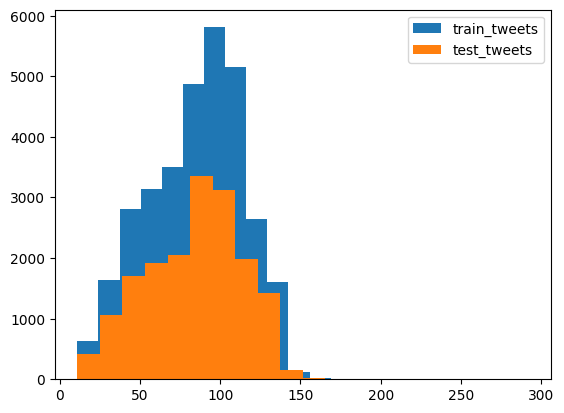

In [ ]:
length_train = train['tweet'].str.len()
length_test = test['tweet'].str.len()
plt.hist(length_train, bins = 20, label = 'train_tweets')
plt.hist(length_test, bins = 20, label = 'test_tweets')
plt.legend()
plt.show()

In [ ]:
combi = pd.concat([train, test], ignore_index=True)
combi.shape

(49159, 3)

In [ ]:
def remove_pattern(input_txt, pattern):
    r = re.findall(pattern, input_txt)
    for i in r:
        input_txt = re.sub(i, "", input_txt)
    return input_txt

In [ ]:
# removing twitter handles
combi['tidy_tweet'] = np.vectorize(remove_pattern)(combi['tweet'], r"@[\w]*")
combi.head()

,id,label,tweet,tidy_tweet
0,1,0.0,@user when a father is dysfunctional and is so selfish he drags his kids into his dysfunction. #run,when a father is dysfunctional and is so selfish he drags his kids into his dysfunction. #run
1,2,0.0,@user @user thanks for #lyft credit i can't use cause they don't offer wheelchair vans in pdx. #disapointed #getthanked,thanks for #lyft credit i can't use cause they don't offer wheelchair vans in pdx. #disapointed #getthanked
2,3,0.0,bihday your majesty,bihday your majesty
3,4,0.0,#model i love u take with u all the time in urð±!!! ðððð ð¦ð¦ð¦,#model i love u take with u all the time in urð±!!! ðððð ð¦ð¦ð¦
4,5,0.0,factsguide: society now #motivation,factsguide: society now #motivation


In [ ]:
# expanding "n't" contractions so negations survive punctuation removal
combi['tidy_tweet'] = combi['tidy_tweet'].str.replace(r"n't\b", " not", regex=True)

# removing punctuations, numbers and special characters
combi['tidy_tweet'] = combi['tidy_tweet'].str.replace("[^a-zA-Z#]", " ", regex=True)
combi.head(10)

,id,label,tweet,tidy_tweet
0,1,0.0,@user when a father is dysfunctional and is so selfish he drags his kids into his dysfunction. #run,when a father is dysfunctional and is so selfish he drags his kids into his dysfunction #run
1,2,0.0,@user @user thanks for #lyft credit i can't use cause they don't offer wheelchair vans in pdx. #disapointed #getthanked,thanks for #lyft credit i ca not use cause they do not offer wheelchair vans in pdx #disapointed #getthanked
2,3,0.0,bihday your majesty,bihday your majesty
3,4,0.0,#model i love u take with u all the time in urð±!!! ðððð ð¦ð¦ð¦,#model i love u take with u all the time in ur
4,5,0.0,factsguide: society now #motivation,factsguide society now #motivation
5,6,0.0,[2/2] huge fan fare and big talking before they leave. chaos and pay disputes when they get there. #allshowandnogo,huge fan fare and big talking before they leave chaos and pay disputes when they get there #allshowandnogo
6,7,0.0,@user camping tomorrow @user @user @user @user @user @user @user dannyâ¦,camping tomorrow danny
7,8,0.0,the next school year is the year for exams.ð¯ can't think about that ð­ #school #exams #hate #imagine #actorslife #revolutionschool #girl,the next school year is the year for exams ca not think about that #school #exams #hate #imagine #actorslife #revolutionschool #girl
8,9,0.0,we won!!! love the land!!! #allin #cavs #champions #cleveland #clevelandcavaliers â¦,we won love the land #allin #cavs #champions #cleveland #clevelandcavaliers
9,10,0.0,@user @user welcome here ! i'm it's so #gr8 !,welcome here i m it s so #gr


In [ ]:
# removing short words (keeping negations, which flip a tweet's meaning)
negations = {'no', 'not', 'nor'}
combi['tidy_tweet'] = combi['tidy_tweet'].apply(lambda x: ' '.join([w for w in x.split() if len(w)>3 or w in negations]))

In [ ]:
# tokenization of tweets
tokenized_tweet = combi['tidy_tweet'].apply(lambda x: x.split()) # tokenizing
tokenized_tweet.head()

,tidy_tweet
0,"[when, father, dysfunctional, selfish, drags, kids, into, dysfunction, #run]"
1,"[thanks, #lyft, credit, not, cause, they, not, offer, wheelchair, vans, #disapointed, #getthanked]"
2,"[bihday, your, majesty]"
3,"[#model, love, take, with, time]"
4,"[factsguide, society, #motivation]"


In [ ]:
# text normalization
from nltk.stem.porter import *
stemmer = PorterStemmer()
tokenized_tweet = tokenized_tweet.apply(lambda x: [stemmer.stem(i) for i in x]) # stemming

In [ ]:
tokenized_tweet = tokenized_tweet.apply(lambda x: ' '.join(x))
combi['tidy_tweet'] = tokenized_tweet

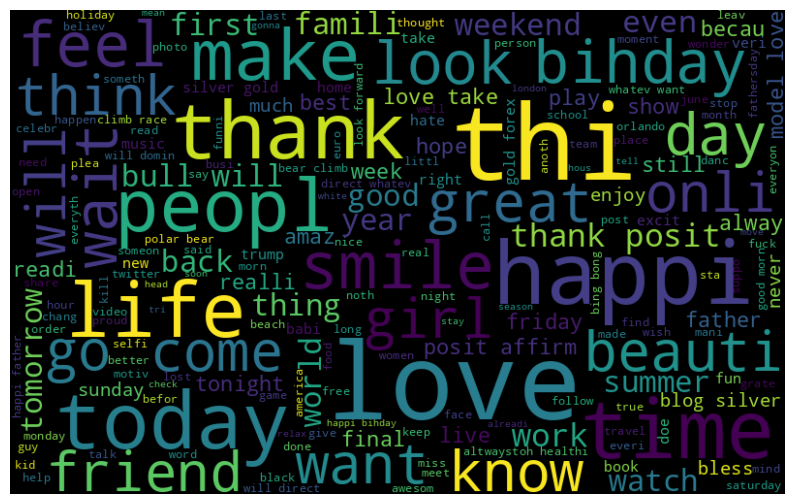

In [ ]:
all_words = ' '.join([text for text in combi['tidy_tweet']])

from wordcloud import WordCloud
wordcloud = WordCloud(width=800, height=500, random_state=21, max_font_size=110).generate(all_words)

plt.figure(figsize=(10, 7))
plt.imshow(wordcloud, interpolation="bilinear")
plt.axis('off')
plt.show()

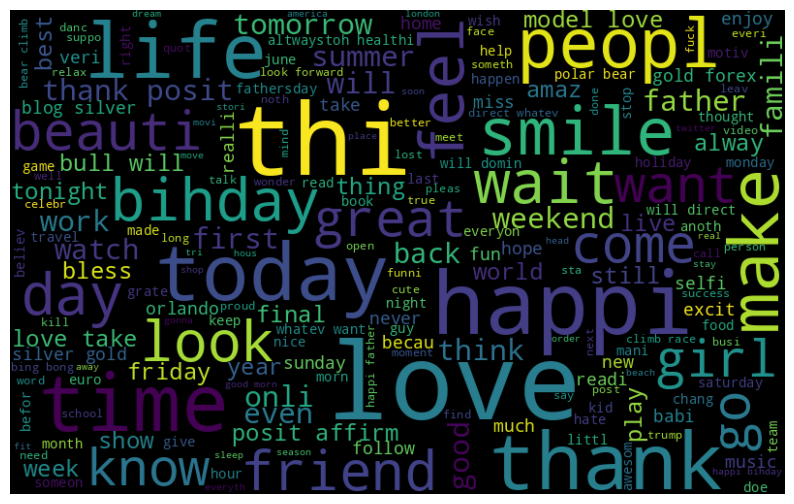

In [ ]:
normal_words =' '.join([text for text in combi['tidy_tweet'][combi['label'] == 0]])

wordcloud = WordCloud(width=800, height=500, random_state=21, max_font_size=110).generate(normal_words)

plt.figure(figsize=(10, 7))
plt.imshow(wordcloud, interpolation="bilinear")
plt.axis('off')
plt.show()

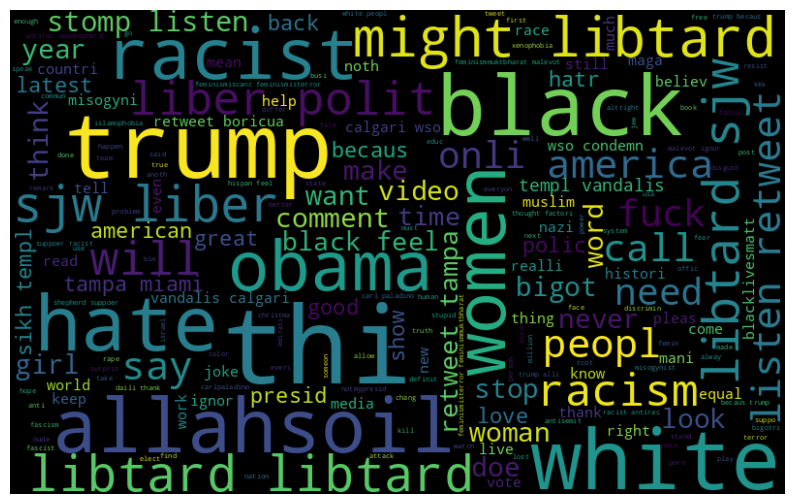

In [ ]:
negative_words = ' '.join([text for text in combi['tidy_tweet'][combi['label'] == 1]])

wordcloud = WordCloud(width=800, height=500, random_state=21, max_font_size=110).generate(negative_words)

plt.figure(figsize=(10, 7))
plt.imshow(wordcloud, interpolation="bilinear")
plt.axis('off')
plt.show()

In [ ]:
# function to collect hashtags
def hashtag_extract(x):
    hashtags = []    # Loop over the words in the tweet
    for i in x:
        ht = re.findall(r"#(\w+)", i)
        hashtags.append(ht)
    return hashtags

# extracting hashtags from non racist/sexist tweets
HT_regular = hashtag_extract(combi['tidy_tweet'][combi['label'] == 0])

# extracting hashtags from racist/sexist tweets
HT_negative = hashtag_extract(combi['tidy_tweet'][combi['label'] == 1])

# unnesting list
HT_regular = sum(HT_regular,[])
HT_negative = sum(HT_negative,[])

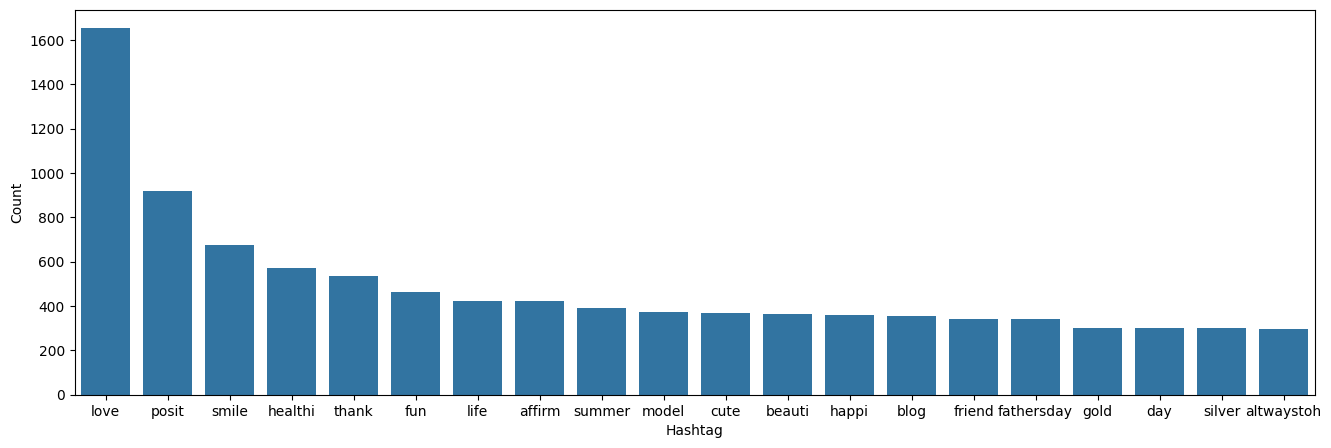

In [ ]:
# non-racist/ sexist tweets
a = nltk.FreqDist(HT_regular)
d = pd.DataFrame({'Hashtag': list(a.keys()), 'Count': list(a.values())})

# selecting top 20 most frequent hashtags
d = d.nlargest(columns="Count", n = 20)

plt.figure(figsize=(16,5))
ax = sns.barplot(data=d, x= "Hashtag", y = "Count")
ax.set(ylabel = 'Count')
plt.show()

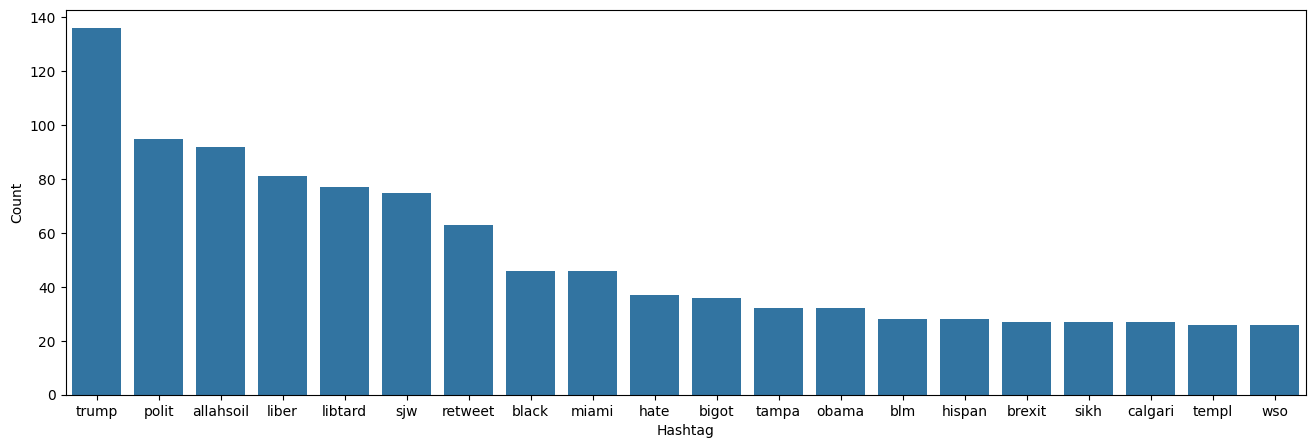

In [ ]:
# racist/ sexist tweets
b = nltk.FreqDist(HT_negative)
e = pd.DataFrame({'Hashtag': list(b.keys()), 'Count': list(b.values())})

# selecting top 20 most frequent hashtags
e = e.nlargest(columns="Count", n = 20)

plt.figure(figsize=(16,5))
ax = sns.barplot(data=e, x= "Hashtag", y = "Count")

In [ ]:
from sklearn.feature_extraction.text import TfidfVectorizer, CountVectorizer
import gensim

In [ ]:
bow_vectorizer = CountVectorizer(max_df=0.90, min_df=2, max_features=1000, stop_words='english')
bow = bow_vectorizer.fit_transform(combi['tidy_tweet'])
bow.shape

(49159, 1000)

In [ ]:
tfidf_vectorizer = TfidfVectorizer(max_df=0.90, min_df=2, max_features=1000, stop_words='english')
tfidf = tfidf_vectorizer.fit_transform(combi['tidy_tweet'])
tfidf.shape

(49159, 1000)

In [ ]:
tokenized_tweet = combi['tidy_tweet'].apply(lambda x: x.split()) # tokenizing

In [ ]:
model_w2v = gensim.models.Word2Vec(
            vector_size=200, # desired no. of features/independent variables
            window=5, # context window size
            min_count=2,
            sg = 1, # 1 for skip-gram model
            hs = 0,
            negative = 10, # for negative sampling
            workers= 2, # no.of cores
            seed = 34)

# building the vocabulary only; training happens once, in the next cell
model_w2v.build_vocab(tokenized_tweet)

In [ ]:
model_w2v.train(tokenized_tweet, total_examples= len(combi['tidy_tweet']), epochs=20)

(6565271, 7659580)

In [ ]:
model_w2v.wv.most_similar(positive="dinner")

[('#cellar', 0.611619770526886),
 ('#avocado', 0.591973602771759),
 ('spaghetti', 0.579216480255127),
 ('reggio', 0.5748468041419983),
 ('#biall', 0.5664873123168945),
 ('spinach', 0.5657541155815125),
 ('dess', 0.5630088448524475),
 ('wynwood', 0.5626572370529175),
 ('noodl', 0.5623338222503662),
 ('fav', 0.5617035627365112)]

In [ ]:
model_w2v.wv.most_similar(positive="trump")

[('potu', 0.5590566992759705),
 ('phoni', 0.5505416989326477),
 ('unstabl', 0.5493616461753845),
 ('donald', 0.54766446352005),
 ('hillari', 0.5463883280754089),
 ('carl', 0.5438345670700073),
 ('#delegaterevolt', 0.5431340336799622),
 ('unfit', 0.5419167280197144),
 ('nomine', 0.538136899471283),
 ('jibe', 0.5375229120254517)]

In [ ]:
model_w2v.wv['food']

array([-0.35437843,  0.14771971,  0.28474557, -0.16978408, -0.036461  ,
       -0.14210072, -0.0427947 , -0.03056171,  0.29217777, -0.3171707 ,
        0.47060597,  0.32379913, -0.210309  , -0.05286365, -0.3551373 ,
        0.00787407,  0.39248675,  0.14779451,  0.02632902, -0.43353084,
       -0.49618974,  0.48216185, -0.36383298, -0.22926354, -0.71364754,
        0.23219648,  0.4021242 ,  0.04812106, -0.36219755, -0.01934622,
       -0.29360828, -1.1874145 ,  0.16209264, -0.5601195 ,  0.38981566,
       -0.73381203, -0.39219242,  0.22994588,  0.0747671 ,  0.01222531,
       -0.10193638, -0.13554981, -0.2427165 ,  0.8246413 , -0.22237697,
        0.39283362,  0.81305236, -0.18897673, -0.22098774, -0.082765  ,
       -0.13358857, -0.06762572,  0.0314353 , -0.7381765 , -0.14000706,
       -0.1389064 , -0.00763164, -0.1483913 ,  0.5026268 ,  0.01556064,
        0.3573605 , -0.01023919,  0.07163313, -0.27777964, -0.34250376,
        0.06628659,  0.6463128 , -0.21906145, -0.15716265, -0.79

In [ ]:
len(model_w2v.wv['food']) #The length of the vector is 200

200

In [ ]:
def word_vector(tokens, size):
    vec = np.zeros(size)
    count = 0.
    for word in tokens:
        try:
            vec += model_w2v.wv[word]
            count += 1.
        except KeyError: # handling the case where the token is not in vocabulary
            continue
    if count != 0:
        vec /= count
    return vec

In [ ]:
wordvec_arrays = np.zeros((len(tokenized_tweet), 200))
for i in range(len(tokenized_tweet)):
    tokens = tokenized_tweet.iloc[i]
    if isinstance(tokens, str):
        tokens = tokens.split()
    wordvec_arrays[i,:] = word_vector(tokens, 200)

wordvec_df = pd.DataFrame(wordvec_arrays)
wordvec_df.shape

(49159, 200)

In [ ]:
from tqdm import tqdm
tqdm.pandas(desc="progress-bar")
from gensim.models.doc2vec import TaggedDocument

In [ ]:
def add_label(twt):
    output = []
    for i, s in zip(twt.index, twt):
        output.append(TaggedDocument(s, ["tweet_" + str(i)]))
    return output

In [ ]:
labeled_tweets = add_label(tokenized_tweet) # label all the tweets

In [ ]:
model_d2v = gensim.models.Doc2Vec(dm=1, # dm = 1 for ‘distributed memory’ model
                                  dm_mean=1, # dm_mean = 1 for using mean of the context word vectors
                                  vector_size=200, # no. of desired features
                                  window=5, # width of the context window
                                  negative=7, # if > 0 then negative sampling will be used
                                  min_count=5, # Ignores all words with total frequency lower than 5.
                                  workers=3, # no. of cores
                                  alpha=0.025, # learning rate (gensim default)
                                  seed = 23)
model_d2v.build_vocab([i for i in tqdm(labeled_tweets)])

100%|██████████| 49159/49159 [00:00<00:00, 3196412.59it/s]


In [ ]:
model_d2v.train(labeled_tweets, total_examples= len(combi['tidy_tweet']), epochs=15)

In [ ]:
docvec_arrays = np.zeros((len(tokenized_tweet), 200))
for i, idx in enumerate(combi.index):
    docvec_arrays[i,:] = model_d2v.dv['tweet_' + str(idx)].reshape((1,200))

In [ ]:
docvec_df = pd.DataFrame(docvec_arrays)
docvec_df.shape

(49159, 200)

In [ ]:
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import train_test_split
from sklearn.metrics import f1_score

In [ ]:
# Extracting train and test BoW features
train_bow = bow[:31962,:]
test_bow = bow[31962:,:]
# splitting data into training and validation set
xtrain_bow, xvalid_bow, ytrain, yvalid = train_test_split(train_bow, train['label'], random_state=42, test_size=0.3)

In [ ]:
lreg = LogisticRegression()

# training the model
lreg.fit(xtrain_bow, ytrain)

prediction = lreg.predict_proba(xvalid_bow) # predicting on the validation set
prediction_int = prediction[:,1] >= 0.3 # if prediction is greater than or equal to 0.3 than 1 else 0
prediction_int = prediction_int.astype(int)

f1_score(yvalid, prediction_int) # calculating f1 score for the validation set

0.5321100917431193

In [ ]:
test_pred = lreg.predict_proba(test_bow)
test_pred_int = test_pred[:,1] >= 0.3
test_pred_int = test_pred_int.astype(int)
test['label'] = test_pred_int

submission = test[['id','label']]
submission.to_csv('sub_lreg_bow.csv', index=False) # writing data to a CSV file

In [ ]:
train_tfidf = tfidf[:31962,:]
test_tfidf = tfidf[31962:,:]

xtrain_tfidf = train_tfidf[ytrain.index]
xvalid_tfidf = train_tfidf[yvalid.index]

lreg.fit(xtrain_tfidf, ytrain)
prediction = lreg.predict_proba(xvalid_tfidf)
prediction_int = prediction[:,1] >= 0.3
prediction_int = prediction_int.astype(int)

f1_score(yvalid, prediction_int) # calculating f1 score for the validation set

0.5464190981432361

In [ ]:
train_d2v = docvec_df.iloc[:31962,:]
test_d2v = docvec_df.iloc[31962:,:]

xtrain_d2v = train_d2v.iloc[ytrain.index,:]
xvalid_d2v = train_d2v.iloc[yvalid.index,:]

lreg.fit(xtrain_d2v, ytrain)
prediction = lreg.predict_proba(xvalid_d2v)
prediction_int = prediction[:,1] >= 0.3
prediction_int = prediction_int.astype(int)

f1_score(yvalid, prediction_int)

0.3700361010830325

In [ ]:
from sklearn import svm

In [ ]:
svc = svm.SVC(kernel='linear', C=1, probability=True).fit(xtrain_bow, ytrain)

prediction = svc.predict_proba(xvalid_bow)

prediction_int = prediction[:,1] >= 0.3
prediction_int = prediction_int.astype(int)

f1_score(yvalid, prediction_int)

0.5115420129270545

In [ ]:
test_pred = svc.predict_proba(test_bow)

test_pred_int = test_pred[:,1] >= 0.3
test_pred_int = test_pred_int.astype(int)

test['label'] = test_pred_int

submission = test[['id','label']]
submission.to_csv('sub_svm_bow.csv', index=False)

In [ ]:
svc = svm.SVC(kernel='linear', C=1, probability=True).fit(xtrain_tfidf, ytrain)

prediction = svc.predict_proba(xvalid_tfidf)
prediction_int = prediction[:,1] >= 0.3
prediction_int = prediction_int.astype(int)

f1_score(yvalid, prediction_int)

0.5082266910420475

In [ ]:
# Extracting train and test Word2Vec features
train_w2v = wordvec_df.iloc[:31962, :]
test_w2v = wordvec_df.iloc[31962:, :]

xtrain_w2v = train_w2v.iloc[ytrain.index, :]
xvalid_w2v = train_w2v.iloc[yvalid.index, :]

svc = svm.SVC(kernel='linear', C=1, probability=True).fit(xtrain_w2v, ytrain)

prediction = svc.predict_proba(xvalid_w2v)
prediction_int = prediction[:,1] >= 0.3
prediction_int = prediction_int.astype(int)

f1_score(yvalid, prediction_int)

0.6181254841208366

In [ ]:
from sklearn.ensemble import RandomForestClassifier

In [ ]:
rf = RandomForestClassifier(n_estimators=400, random_state=11).fit(xtrain_bow, ytrain)
prediction = rf.predict_proba(xvalid_bow)
prediction_int = prediction[:,1] >= 0.3
prediction_int = prediction_int.astype(int)

# validation score
f1_score(yvalid, prediction_int)

0.5100748416810593

In [ ]:
test_pred = rf.predict_proba(test_bow)
test_pred_int = test_pred[:,1] >= 0.3
test_pred_int = test_pred_int.astype(int)
test['label'] = test_pred_int

submission = test[['id','label']]
submission.to_csv('sub_rf_bow.csv', index=False)

In [ ]:
rf = RandomForestClassifier(n_estimators=400, random_state=11).fit(xtrain_tfidf, ytrain)
prediction = rf.predict_proba(xvalid_tfidf)
prediction_int = prediction[:,1] >= 0.3
prediction_int = prediction_int.astype(int)

f1_score(yvalid, prediction_int)

0.5657794676806084

In [ ]:
rf = RandomForestClassifier(n_estimators=400, random_state=11).fit(xtrain_w2v, ytrain)
prediction = rf.predict_proba(xvalid_w2v)
prediction_int = prediction[:,1] >= 0.3
prediction_int = prediction_int.astype(int)

f1_score(yvalid, prediction_int)

0.6366666666666667

In [ ]:
rf = RandomForestClassifier(n_estimators=400, random_state=11).fit(xtrain_d2v, ytrain)
prediction = rf.predict_proba(xvalid_d2v)
prediction_int = prediction[:,1] >= 0.3
prediction_int = prediction_int.astype(int)

f1_score(yvalid, prediction_int)

0.4903442485306465

In [ ]:
from xgboost import XGBClassifier

In [ ]:
xgb_model = XGBClassifier(max_depth=6, n_estimators=1000).fit(xtrain_bow, ytrain)
prediction = xgb_model.predict_proba(xvalid_bow)
prediction_int = prediction[:,1] >= 0.3
prediction_int = prediction_int.astype(int)

f1_score(yvalid, prediction_int)

0.5578125

In [ ]:
test_pred = xgb_model.predict_proba(test_bow)
test_pred_int = test_pred[:,1] >= 0.3
test_pred_int = test_pred_int.astype(int)
test['label'] = test_pred_int

submission = test[['id','label']]
submission.to_csv('sub_xgb_bow.csv', index=False)

In [ ]:
xgb_clf = XGBClassifier(max_depth=6, n_estimators=1000).fit(xtrain_tfidf, ytrain)
prediction = xgb_clf.predict_proba(xvalid_tfidf)
prediction_int = prediction[:,1] >= 0.3
prediction_int = prediction_int.astype(int)

f1_score(yvalid, prediction_int)

0.5584

In [ ]:
xgb_clf = XGBClassifier(max_depth=6, n_estimators=1000, nthread= 3).fit(xtrain_w2v, ytrain)
prediction = xgb_clf.predict_proba(xvalid_w2v)
prediction_int = prediction[:,1] >= 0.3
prediction_int = prediction_int.astype(int)

f1_score(yvalid, prediction_int)

0.6728033472803348

In [ ]:
xgb_clf = XGBClassifier(max_depth=6, n_estimators=1000, nthread= 3).fit(xtrain_d2v, ytrain)
prediction = xgb_clf.predict_proba(xvalid_d2v)
prediction_int = prediction[:,1] >= 0.3
prediction_int = prediction_int.astype(int)

f1_score(yvalid, prediction_int)

0.482886216466235

In [ ]:
import xgboost as xgb

In [ ]:
dtrain = xgb.DMatrix(xtrain_w2v, label=ytrain)
dvalid = xgb.DMatrix(xvalid_w2v, label=yvalid)
dtest = xgb.DMatrix(test_w2v)

In [ ]:
# Parameters that we are going to tune
params = {
    'objective':'binary:logistic',
    'max_depth':6,
    'min_child_weight': 1,
    'eta':.3,
    'subsample': 1,
    'colsample_bytree': 1
 }

In [ ]:
def custom_eval(preds, dtrain):
    labels = dtrain.get_label().astype(int)
    preds = (preds >= 0.3).astype(int)
    return [('f1_score', f1_score(labels, preds))]

In [ ]:
# Tuning max_depth and min_child_weight

gridsearch_params = [
    (max_depth, min_child_weight)
    for max_depth in range(6,10)
     for min_child_weight in range(5,8)
 ]

In [ ]:
max_f1 = 0. # initializing with 0
best_params = None
for max_depth, min_child_weight in gridsearch_params:
    print("CV with max_depth={}, min_child_weight={}".format(
                             max_depth,
                             min_child_weight))
    # Update our parameters
    params['max_depth'] = max_depth
    params['min_child_weight'] = min_child_weight

    # Cross-validation
    cv_results = xgb.cv(params,
        dtrain,
        custom_metric=custom_eval,
        num_boost_round=200,
        maximize=True,
        seed=16,
        nfold=5,
        early_stopping_rounds=10
    )

    # Finding best F1 Score
    mean_f1 = cv_results['test-f1_score-mean'].max()
    boost_rounds = cv_results['test-f1_score-mean'].argmax()
    print("\tF1 Score {} for {} rounds".format(mean_f1, boost_rounds))
    if mean_f1 > max_f1:
        max_f1 = mean_f1
        best_params = (max_depth, min_child_weight)

CV with max_depth=6, min_child_weight=5
	F1 Score 0.6696899999999999 for 84 rounds
CV with max_depth=6, min_child_weight=6
	F1 Score 0.6698042000000001 for 91 rounds
CV with max_depth=6, min_child_weight=7
	F1 Score 0.6611326 for 77 rounds
CV with max_depth=7, min_child_weight=5
	F1 Score 0.6649556000000001 for 64 rounds
CV with max_depth=7, min_child_weight=6
	F1 Score 0.6706988 for 55 rounds
CV with max_depth=7, min_child_weight=7
	F1 Score 0.6709320000000001 for 80 rounds
CV with max_depth=8, min_child_weight=5
	F1 Score 0.6548858 for 47 rounds
CV with max_depth=8, min_child_weight=6
	F1 Score 0.6747408000000001 for 78 rounds
CV with max_depth=8, min_child_weight=7
	F1 Score 0.6548562 for 32 rounds
CV with max_depth=9, min_child_weight=5
	F1 Score 0.6726266 for 89 rounds
CV with max_depth=9, min_child_weight=6
	F1 Score 0.6577548 for 55 rounds
CV with max_depth=9, min_child_weight=7
	F1 Score 0.6680122 for 44 rounds


In [ ]:
print("Best params: {}, {}, F1 Score: {}".format(best_params[0], best_params[1], max_f1))

Best params: 8, 6, F1 Score: 0.6747408000000001


In [ ]:
# Updating max_depth and min_child_weight parameters.

params['max_depth'] = best_params[0]
params['min_child_weight'] = best_params[1]

In [ ]:
# Tuning subsample and colsample

gridsearch_params = [
    (subsample, colsample)
    for subsample in [i/10. for i in range(5,10)]
    for colsample in [i/10. for i in range(5,10)] ]

In [ ]:
max_f1 = 0.
best_params = None
for subsample, colsample in gridsearch_params:
    print("CV with subsample={}, colsample={}".format(
                             subsample,
                             colsample))

     # Update our parameters
    params['colsample_bytree'] = colsample
    params['subsample'] = subsample
    cv_results = xgb.cv(
        params,
        dtrain,
        custom_metric=custom_eval,
        num_boost_round=200,
        maximize=True,
        seed=16,
        nfold=5,
        early_stopping_rounds=10
    )

     # Finding best F1 Score
    mean_f1 = cv_results['test-f1_score-mean'].max()
    boost_rounds = cv_results['test-f1_score-mean'].argmax()
    print("\tF1 Score {} for {} rounds".format(mean_f1, boost_rounds))
    if mean_f1 > max_f1:
        max_f1 = mean_f1
        best_params = (subsample, colsample)

CV with subsample=0.5, colsample=0.5
	F1 Score 0.6512112 for 47 rounds
CV with subsample=0.5, colsample=0.6
	F1 Score 0.6289332 for 23 rounds
CV with subsample=0.5, colsample=0.7
	F1 Score 0.6652568 for 115 rounds
CV with subsample=0.5, colsample=0.8
	F1 Score 0.6444455999999998 for 53 rounds
CV with subsample=0.5, colsample=0.9
	F1 Score 0.6358699999999999 for 39 rounds
CV with subsample=0.6, colsample=0.5
	F1 Score 0.6483648000000001 for 59 rounds
CV with subsample=0.6, colsample=0.6
	F1 Score 0.6605998000000001 for 59 rounds
CV with subsample=0.6, colsample=0.7
	F1 Score 0.6494676 for 25 rounds
CV with subsample=0.6, colsample=0.8
	F1 Score 0.6594822 for 61 rounds
CV with subsample=0.6, colsample=0.9
	F1 Score 0.6662142 for 79 rounds
CV with subsample=0.7, colsample=0.5
	F1 Score 0.6597250000000001 for 71 rounds
CV with subsample=0.7, colsample=0.6
	F1 Score 0.6597336 for 60 rounds
CV with subsample=0.7, colsample=0.7
	F1 Score 0.6611426 for 55 rounds
CV with subsample=0.7, colsampl

In [ ]:
print("Best params: {}, {}, F1 Score: {}".format(best_params[0], best_params[1], max_f1))

Best params: 0.8, 0.8, F1 Score: 0.6775844000000001


In [ ]:
# Updating subsample and colsample_bytree

params['subsample'] = best_params[0]
params['colsample_bytree'] = best_params[1]

In [ ]:
# Tuning the learning rate.

max_f1 = 0.
best_params = None
best_rounds = None
for eta in [.3, .2, .1, .05, .01, .005]:
    print("CV with eta={}".format(eta))
     # Update ETA
    params['eta'] = eta

     # Run CV
    cv_results = xgb.cv(
        params,
        dtrain,
        custom_metric= custom_eval,
        num_boost_round=1000,
        maximize=True,
        seed=16,
        nfold=5,
        early_stopping_rounds=100 # small learning rates need many rounds before any prediction crosses 0.3
    )
    # Finding best F1 Score
    mean_f1 = cv_results['test-f1_score-mean'].max()
    boost_rounds = cv_results['test-f1_score-mean'].argmax()
    print("\tF1 Score {} for {} rounds".format(mean_f1, boost_rounds))
    if mean_f1 > max_f1:
        max_f1 = mean_f1
        best_params = eta
        best_rounds = boost_rounds + 1
print("Best params: {}, F1 Score: {}".format(best_params, max_f1))

# the loop leaves the last eta tried in params, so set the best one explicitly
params['eta'] = best_params

CV with eta=0.3
	F1 Score 0.6936316 for 304 rounds
CV with eta=0.2
	F1 Score 0.6898268 for 121 rounds
CV with eta=0.1
	F1 Score 0.6966870000000001 for 455 rounds
CV with eta=0.05
	F1 Score 0.6892862000000001 for 214 rounds
CV with eta=0.01
	F1 Score 0.6840833999999999 for 970 rounds
CV with eta=0.005
	F1 Score 0.662753 for 981 rounds
Best params: 0.1, F1 Score: 0.6966870000000001


In [ ]:
params

{'objective': 'binary:logistic',
 'max_depth': 8,
 'min_child_weight': 6,
 'eta': 0.1,
 'subsample': 0.8,
 'colsample_bytree': 0.8}

In [ ]:
# training for the number of rounds picked by CV; the validation set is only
# monitored, not used for early stopping, so its F1 below stays unbiased
xgb_model = xgb.train(
    params,
    dtrain,
    custom_metric= custom_eval,
    num_boost_round= best_rounds,
    maximize=True,
    evals=[(dvalid, "Validation")],
    verbose_eval=25
 )

[0]	Validation-logloss:0.23356	Validation-f1_score:0.00000
[25]	Validation-logloss:0.13718	Validation-f1_score:0.60318
[50]	Validation-logloss:0.12666	Validation-f1_score:0.65504
[75]	Validation-logloss:0.12269	Validation-f1_score:0.67403
[100]	Validation-logloss:0.12181	Validation-f1_score:0.67675
[125]	Validation-logloss:0.12284	Validation-f1_score:0.66452
[150]	Validation-logloss:0.12366	Validation-f1_score:0.66938
[175]	Validation-logloss:0.12497	Validation-f1_score:0.68182
[200]	Validation-logloss:0.12663	Validation-f1_score:0.67488
[225]	Validation-logloss:0.12846	Validation-f1_score:0.67707
[250]	Validation-logloss:0.13009	Validation-f1_score:0.67603
[275]	Validation-logloss:0.13133	Validation-f1_score:0.67273
[300]	Validation-logloss:0.13210	Validation-f1_score:0.67934
[325]	Validation-logloss:0.13339	Validation-f1_score:0.68369
[350]	Validation-logloss:0.13467	Validation-f1_score:0.68264
[375]	Validation-logloss:0.13546	Validation-f1_score:0.68208
[400]	Validation-logloss:0.13

In [ ]:
prediction = xgb_model.predict(dvalid)
prediction_int = (prediction >= 0.3).astype(int)

f1_score(yvalid, prediction_int) # validation F1 of the tuned model

0.6743993371996686

In [ ]:
test_pred = xgb_model.predict(dtest)
test['label'] = (test_pred >= 0.3).astype(int)

submission = test[['id','label']]
submission.to_csv('sub_xgb_w2v_finetuned.csv', index=False)